In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# EDA I guess

In [3]:
train_df = pd.read_csv("casas_entrenamiento.csv")
predict_df = pd.read_csv("casas_predecir.csv")
train_df.set_index("id", inplace=True)
predict_df.set_index("id", inplace=True)
train_df.info()
train_df.head()


<class 'pandas.DataFrame'>
Index: 61577 entries, vz/dYJl3t6dAAhuCMR9pFg== to HRbpEtxpE+UlK4FfpzZ0eA==
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ad_type          61577 non-null  str    
 1   start_date       61577 non-null  str    
 2   end_date         61577 non-null  str    
 3   created_on       61577 non-null  str    
 4   lat              51730 non-null  float64
 5   lon              51516 non-null  float64
 6   l1               61577 non-null  str    
 7   l2               61577 non-null  str    
 8   l3               58469 non-null  str    
 9   l4               22976 non-null  str    
 10  l5               520 non-null    str    
 11  l6               0 non-null      float64
 12  rooms            38134 non-null  float64
 13  bedrooms         32007 non-null  float64
 14  bathrooms        56553 non-null  float64
 15  surface_total    32952 non-null  float64
 16  surface_covered  37370 non-null 

,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
vz/dYJl3t6dAAhuCMR9pFg==,Propiedad,2020-03-21,9999-12-31,2020-03-21,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,NaN,NaN,NaN,4.0,3.0,2.0,NaN,NaN,NaN,"Casa en Venta en Primera sección, Tigre U$S 19...",no paga
7WuevfRjW78WomnkinRSAA==,Propiedad,2019-05-22,9999-12-31,2019-05-22,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,NaN,NaN,NaN,3.0,NaN,1.0,120.0,105.0,Mensual,Casa en venta en Tigre con dos dormitorios y j...,no paga
zZlOOuCPY//CPsAuwgfICA==,Propiedad,2019-10-13,2019-10-28,2019-10-13,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,NaN,NaN,NaN,NaN,2.0,2.0,230.0,230.0,NaN,Casa de 3 ambientes en Venta en Villa crespo,no paga
dZmdfoiNyUCOgDbRXIuPCg==,Propiedad,2020-01-10,9999-12-31,2020-01-10,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,NaN,NaN,NaN,4.0,NaN,1.0,63.0,63.0,Mensual,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz,no paga
nt8/Rc6J4m3all/FkfX0gQ==,Propiedad,2019-04-03,2020-04-16,2019-04-03,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,8.0,6.0,NaN,NaN,NaN,NaN,Inmueble en block en Venta. 8 Amb. 6 Dor,no paga


Distribucion de la variable target:
paga_comision
no paga    88.898452
paga       11.101548
Name: proportion, dtype: float64


<Axes: xlabel='paga_comision', ylabel='count'>

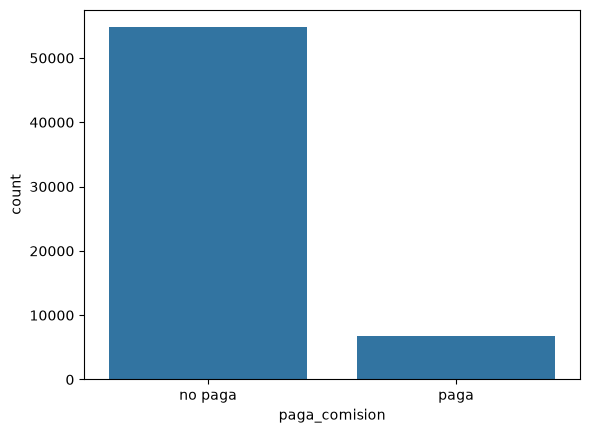

In [4]:
## Target distribution 88/11
distibution = train_df["paga_comision"].value_counts(normalize=True)*100
print("Distribucion de la variable target:")
print(distibution)
sns.countplot(x="paga_comision", data=train_df)


In [5]:
## Nulls as porcentage of the total dataset
print("Total rows: ", train_df.shape[0])
train_df.isna().mean()*100
## L5 & L6 are basically all empty.


Total rows:  61577


ad_type              0.000000
start_date           0.000000
end_date             0.000000
created_on           0.000000
lat                 15.991360
lon                 16.338893
l1                   0.000000
l2                   0.000000
l3                   5.047339
l4                  62.687367
l5                  99.155529
l6                 100.000000
rooms               38.071033
bedrooms            48.021177
bathrooms            8.158890
surface_total       46.486513
surface_covered     39.311756
price_period        63.913474
title                0.000000
paga_comision        0.000000
dtype: float64

## Trying to get outliers I found that maybe I divided by 0. So checking that. Also negatives

In [6]:
X = train_df.drop(columns="paga_comision")
X_numeric = X.select_dtypes(include="number")
value_counts = pd.DataFrame({
    "zeros": (X_numeric == 0).sum(),
    "negatives": (X_numeric < 0).sum(),
})

value_counts

,zeros,negatives
lat,0,51591
lon,0,51516
l6,0,0
rooms,0,0
bedrooms,697,1
bathrooms,0,0
surface_total,42,2
surface_covered,0,1


In [7]:
## Special case where bedrooms are negative, for some reason.
train_df.loc[train_df["bedrooms"] < 0]

,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
wY/NFLCWKLeg0dxmP+y0Yw==,Propiedad,2019-07-16,9999-12-31,2019-07-16,-34.641356,-58.706481,Argentina,Bs.As. G.B.A. Zona Oeste,Ituzaingó,San Alberto,NaN,NaN,NaN,-2.0,NaN,-200.0,-170.0,Mensual,"Venta de casa, 3 ambientes, Ituzaingo Norte.",no paga


c:\Users\tcamb\Desktop\Main Hub\Universidad\Ciencia de datos\3670-UNLaM-CD\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
c:\Users\tcamb\Desktop\Main Hub\Universidad\Ciencia de datos\3670-UNLaM-CD\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
c:\Users\tcamb\Desktop\Main Hub\Universidad\Ciencia de datos\3670-UNLaM-CD\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


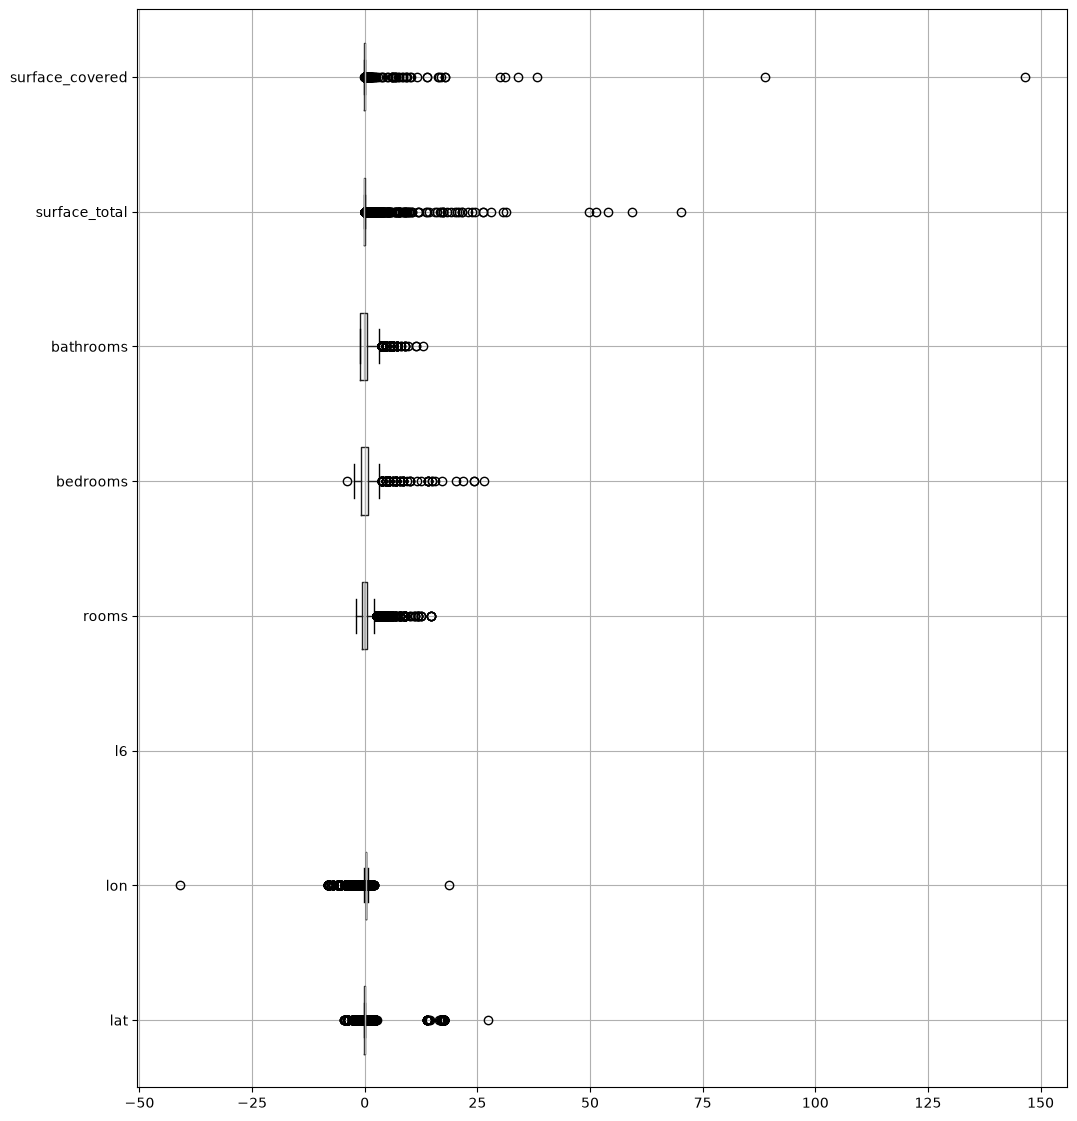

lat                16821
lon                12790
surface_total       3009
surface_covered     1904
rooms                815
bathrooms            372
bedrooms             125
l6                     0
dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

# Scale for a readable boxplot
X_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index,
)

X_scaled.boxplot(vert=False, figsize=(12, 14))
plt.show()

q1 = X_numeric.quantile(0.25)
q3 = X_numeric.quantile(0.75)
iqr = q3 - q1

outlier_counts = (
    X_numeric.lt(q1 - 1.5 * iqr)
    | X_numeric.gt(q3 + 1.5 * iqr)
).sum().sort_values(ascending=False)

print(outlier_counts)

## I want to zoom in on bathrooms


,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
DbECY5a/YlMHkEY7MlH3Qw==,Propiedad,2019-09-02,9999-12-31,2019-09-02,-31.132033,-64.465498,Argentina,Córdoba,Punilla,NaN,NaN,NaN,NaN,NaN,11.0,NaN,710.0,Mensual,Hotel boutique de Estilo Colonial - Excelente ...,no paga
w7URX3djQMBF5jLpH8WkTg==,Propiedad,2020-04-10,9999-12-31,2020-04-10,-34.669079,-58.617542,Argentina,Bs.As. G.B.A. Zona Oeste,Morón,NaN,NaN,NaN,3.0,2.0,11.0,NaN,NaN,NaN,Casa en Venta en Moron Sur,no paga
3fFmWbVzRTNTiV7baP6t9A==,Propiedad,2019-12-13,2019-12-20,2019-12-13,-34.666953,-58.379378,Argentina,Bs.As. G.B.A. Zona Sur,Avellaneda,NaN,NaN,NaN,20.0,13.0,13.0,613.0,613.0,NaN,VENTA CASA 613M2 IDEAL USO COMERCIAL,paga
MZZ56SHXH189yvfI/ZiBUg==,Propiedad,2019-04-30,9999-12-31,2019-04-30,NaN,NaN,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,Benavidez,NaN,NaN,NaN,8.0,11.0,3408.0,463.0,NaN,"Casa 3408m² con Cochera en LUJAN, Río 2100, Ti...",paga
y9R1/MH4xaifOV3Q98pr0Q==,Propiedad,2020-03-14,9999-12-31,2020-03-14,-34.913733,-54.864977,Uruguay,Maldonado,La Barra,NaN,NaN,NaN,8.0,7.0,11.0,NaN,700.0,Mensual,7 DORMITORIOS O MAS | LOS DESTINOS,paga
ibrhXeZm6QriML/m7LbW0w==,Propiedad,2019-09-25,9999-12-31,2019-09-25,-32.943008,-60.637024,Argentina,Santa Fe,Rosario,NaN,NaN,NaN,NaN,NaN,13.0,865.0,NaN,Mensual,Casa - Rosario,paga
Su620Iho9cXJusFQOK+SAQ==,Propiedad,2019-07-16,9999-12-31,2019-07-16,NaN,NaN,Argentina,Bs.As. G.B.A. Zona Norte,Vicente López,Vicente López,NaN,NaN,NaN,5.0,11.0,800.0,1200.0,NaN,"Casa 800m² con Cochera en CAMPOS, Gaspar 400, ...",paga
/V3EMxt1YC5ZAoTJffUFvg==,Propiedad,2019-09-07,2019-12-06,2019-09-07,-34.629059,-58.467872,Argentina,Capital Federal,Flores,NaN,NaN,NaN,15.0,NaN,11.0,418.0,368.0,Mensual,Clásica Casona en venta - Flores,paga
khBGKJ+cEkpYSqhA5ufT+g==,Propiedad,2019-09-21,2019-12-23,2019-09-21,-34.618485,-58.377993,Argentina,Capital Federal,San Telmo,NaN,NaN,NaN,NaN,16.0,18.0,NaN,943.0,NaN,ESTADOS UNIDOS 800,paga


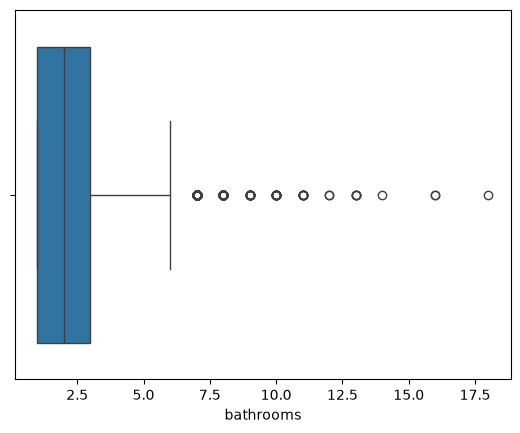

In [9]:
bathrooms = X_numeric["bathrooms"]
sns.boxplot(x=bathrooms)
train_df.loc[train_df["bathrooms"] > 10]

A large number of bathrooms are not necessarily an input error, some houses may indeed have 17 bathrooms. Large numbers for surfaces however do seem to be input errors. Let's inspect further

In [10]:
threshold = train_df["surface_total"].quantile(0.995)
rows_above = train_df.loc[
    train_df["surface_total"] > threshold
].sort_values("surface_total", ascending=False)
print(f"Rows above threshold: {len(rows_above)}")
display(rows_above)



Rows above threshold: 165


,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
oInKbhuquyf166H8WpMzgQ==,Propiedad,2019-12-18,2020-02-03,2019-12-18,NaN,NaN,Argentina,Bs.As. G.B.A. Zona Norte,Pilar,Villa Rosa,NaN,NaN,NaN,NaN,NaN,200000.0,NaN,NaN,"Casa 200000m² en CHUBUT, Pilar, Villa Rosa, po...",paga
WzKWssHxvFGb51Lszu/lIw==,Propiedad,2019-10-21,9999-12-31,2019-10-21,-34.572222,-58.518417,Argentina,Bs.As. G.B.A. Zona Norte,General San Martín,NaN,NaN,NaN,3.0,2.0,1.0,169000.0,100.0,NaN,CASA 3 AMB CON JARDIN AL FRENTE Y GARAJE,no paga
TMA30eFFBCPQTG5oNNoptg==,Propiedad,2019-06-16,9999-12-31,2019-06-16,-34.388195,-58.770989,Argentina,Bs.As. G.B.A. Zona Norte,Escobar,Country Maschwitz Privado,NaN,NaN,NaN,NaN,2.0,154000.0,113.0,Mensual,Casa - Maschwitz Privado oportunidad,no paga
suexxqW0Rm0MgRt/ztlNCA==,Propiedad,2019-11-14,2019-11-23,2019-11-14,-33.005047,-60.657578,Argentina,Santa Fe,Rosario,NaN,NaN,NaN,4.0,2.0,1.0,146600.0,142600.0,NaN,VENTA CASA INTERNA 2/3 DORMITORIOS TIRO SUIZO,no paga
KZYEp/DmxQinDx8XGgFVIw==,Propiedad,2020-02-15,2020-04-01,2020-02-15,-32.167760,-64.472500,Argentina,Córdoba,Villa Rumipal,NaN,NaN,NaN,19.0,6.0,5.0,142170.0,700.0,NaN,CASA DE CATEGORÍA 6dorm. VILLA RUMIPAL CALAMUC...,paga
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Po8awWNB732yrhbdaPvjMA==,Propiedad,2020-02-11,9999-12-31,2020-02-11,-34.884654,-55.048505,Uruguay,Maldonado,Punta Ballena,NaN,NaN,NaN,NaN,5.0,5.0,7000.0,700.0,NaN,Espectacular casa sobre la playa,paga
D9dv3A8ElYP6xlpCQ8uOhw==,Propiedad,2019-10-10,2019-10-13,2019-10-10,NaN,NaN,Argentina,Mendoza,Mendoza,NaN,NaN,NaN,5.0,4.0,4.0,6992.0,325.0,NaN,"Casa quinta con frutales en Tunuyán, sobre Rut...",no paga
dX/HdbGALr0N9ff3lgNdIg==,Propiedad,2019-10-15,2020-03-02,2019-10-15,-31.361412,-64.582916,Argentina,Córdoba,Tanti,NaN,NaN,NaN,5.0,NaN,4.0,6697.0,NaN,NaN,"Contiguo A Asociación Bancaria, Camino A Tanti...",no paga


Also not necessarily input errors. I see a few input errors or low info rows but not enough to cap/remove

## Near duplicates

In [11]:
tmp = train_df.copy()
tmp["title_norm"] = (
    tmp["title"].fillna("")
    .str.lower()
    .str.replace(r"[^a-z0-9áéíóúñ]+", " ", regex=True)
    .str.strip()
)

group_size = tmp.groupby(
    ["title_norm", "rooms"], dropna=False
)["title_norm"].transform("size")

candidates = tmp.loc[
    tmp["title_norm"].ne("") & group_size.gt(1),
    ["title", "title_norm", "rooms", "l3", "surface_total",
     "lat", "lon", "paga_comision"]
].sort_values(["title_norm", "rooms"])

display(candidates)

,title,title_norm,rooms,l3,surface_total,lat,lon,paga_comision
id,,,,,,,,
poihFrqVYgmTVY+gTQTYsg==,1 DORM | TABARE al 1400,1 dorm tabare al 1400,2.0,Ituzaingó,36.0,-34.609528,-58.703510,no paga
9R6q8EsfrpffYoGohTm8uA==,1 DORM | TABARE al 1400,1 dorm tabare al 1400,2.0,Ituzaingó,36.0,-34.609528,-58.703510,no paga
J8EonaMHqP7bcXKDtIiM7A==,10 E/ 41 100 - U$D 136.000 - Casa en Venta,10 e 41 100 u d 136 000 casa en venta,NaN,La Plata,NaN,-34.911465,-57.961170,no paga
LWRpLZ7+UDZgnbYs/LLo0g==,10 E/ 41 100 - U$D 136.000 - Casa en Venta,10 e 41 100 u d 136 000 casa en venta,NaN,La Plata,NaN,-34.911465,-57.961170,no paga
wL43Lw1At+AAb4zxXHcfcw==,11 E/ 527 Y 500 - U$D 370.000 - Casa en Venta,11 e 527 y 500 u d 370 000 casa en venta,NaN,La Plata,NaN,-34.900375,-57.978058,no paga
...,...,...,...,...,...,...,...,...
U4rK8LkQs+fOdYF/ReVWgg==,Z/ Parque Luro - V. Lopez y Planes y Rio Negro...,z parque luro v lopez y planes y rio negro apt...,4.0,Mar del Plata,NaN,-37.974069,-57.558971,no paga
q/FnFyZ8qxeS82J/XKrfsg==,Zeballos 400 - U$D 50.000 - Casa en Venta,zeballos 400 u d 50 000 casa en venta,1.0,San Vicente,NaN,-34.985268,-58.370674,no paga
O/gOwmLuMjpdJr1cn6A5YQ==,Zeballos 400 - U$D 50.000 - Casa en Venta,zeballos 400 u d 50 000 casa en venta,1.0,San Vicente,NaN,-34.985268,-58.370674,no paga


In [12]:
key = ["title", "start_date", "end_date"]

mask = (
    train_df["title"].notna()
    & train_df["title"].str.strip().ne("")
    & train_df.duplicated(subset=key, keep=False)
)

display(train_df.loc[mask].sort_values(key))
print(f"Matching rows: {mask.sum()}")

,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
hBO8vxdztmUbotbFAgE5AQ==,Propiedad,2019-09-22,2019-12-23,2019-09-22,-34.614378,-58.585776,Argentina,Bs.As. G.B.A. Zona Oeste,Morón,El Palomar,NaN,NaN,NaN,3.0,2.0,416.0,230.0,NaN,"****CASA EN VENTA, EL PALOMAR, MORON****",no paga
n6L+78YAPB1Dc8RdMuhIBg==,Propiedad,2019-09-22,2019-12-23,2019-09-22,-34.614378,-58.585776,Argentina,Bs.As. G.B.A. Zona Oeste,Morón,El Palomar,NaN,NaN,NaN,3.0,2.0,416.0,230.0,NaN,"****CASA EN VENTA, EL PALOMAR, MORON****",no paga
tMo8KSvjjgj5yG/AN6QulA==,Propiedad,2020-02-15,2020-02-16,2020-02-15,-34.634178,-58.464941,Argentina,Capital Federal,Flores,NaN,NaN,NaN,NaN,7.0,2.0,367.0,200.0,Mensual,"****Oportunidad venta Casa de Época Flores, **...",no paga
Qdm++yUPm+jUS7FGu+wKKQ==,Propiedad,2020-02-15,2020-02-16,2020-02-15,-34.634178,-58.464941,Argentina,Capital Federal,Flores,NaN,NaN,NaN,NaN,7.0,2.0,367.0,200.0,Mensual,"****Oportunidad venta Casa de Época Flores, **...",no paga
qNr/qe807UtgYkhFPpOrNA==,Propiedad,2019-10-22,9999-12-31,2019-10-22,-34.554759,-58.673058,Argentina,Bs.As. G.B.A. Zona Norte,San Miguel,Bella Vista,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mensual,**CHALET EN VENTA EN BELLA VISTA**,no paga
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10C3L7I57Vx5wktY4SZJuA==,Propiedad,2019-11-26,9999-12-31,2019-11-26,-34.375627,-59.838935,Argentina,Buenos Aires Interior,Carmen de Areco,NaN,NaN,NaN,NaN,3.0,1.0,120.0,320.0,NaN,venta de casa en Carmen de Areco,no paga
pTGd1zuMqRtWtZS8vhtL6Q==,Propiedad,2019-11-26,9999-12-31,2019-11-26,-34.374780,-59.826318,Argentina,Buenos Aires Interior,Carmen de Areco,NaN,NaN,NaN,NaN,3.0,2.0,220.0,250.0,NaN,venta de casa en zona centrica en Carmen de Areco,no paga
7YeIHhwxkVWTDXwY4meX1w==,Propiedad,2019-11-26,9999-12-31,2019-11-26,-34.375725,-59.825712,Argentina,Buenos Aires Interior,Carmen de Areco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,venta de casa en zona centrica en Carmen de Areco,no paga


Matching rows: 8943


In [13]:
key = ["title", "start_date", "end_date"]

has_title = (
    train_df["title"].notna()
    & train_df["title"].str.strip().ne("")
)

remove_mask = (
    has_title
    & train_df.duplicated(subset=key, keep="first")
)

train_df_dedup = train_df.loc[~remove_mask].copy()

print(f"Rows removed: {remove_mask.sum()}")
print(f"Rows remaining: {len(train_df_dedup)}")

Rows removed: 6319
Rows remaining: 55258


About 6.3k near duplicate rows excluced using title & start & end

In [14]:
key = ["title", "start_date", "end_date", "rooms", "l3"]

has_title = (
    train_df["title"].notna()
    & train_df["title"].str.strip().ne("")
)

remove_mask = (
    has_title
    & train_df.duplicated(subset=key, keep="first")
)

train_df_dedup = train_df.loc[~remove_mask].copy()

print(f"Rows removed: {remove_mask.sum()}")
print(f"Rows remaining: {len(train_df_dedup)}")

Rows removed: 4238
Rows remaining: 57339


4.2k near duplicate rows excluced using title, start, end, rooms & l3. Seems better

## Distribution of price_period

In [15]:
distibution = train_df["price_period"].value_counts(normalize=True)*100
print("Distribucion de la variable price_period:")
print(distibution)
train_df.notna

Distribucion de la variable price_period:
price_period
Mensual    100.0
Name: proportion, dtype: float64


<bound method DataFrame.notna of                             ad_type  start_date    end_date  created_on  \
id                                                                        
vz/dYJl3t6dAAhuCMR9pFg==  Propiedad  2020-03-21  9999-12-31  2020-03-21   
7WuevfRjW78WomnkinRSAA==  Propiedad  2019-05-22  9999-12-31  2019-05-22   
zZlOOuCPY//CPsAuwgfICA==  Propiedad  2019-10-13  2019-10-28  2019-10-13   
dZmdfoiNyUCOgDbRXIuPCg==  Propiedad  2020-01-10  9999-12-31  2020-01-10   
nt8/Rc6J4m3all/FkfX0gQ==  Propiedad  2019-04-03  2020-04-16  2019-04-03   
...                             ...         ...         ...         ...   
jXrEh4YhxhnqJ5v5SjFgKQ==  Propiedad  2020-02-13  2020-04-28  2020-02-13   
b+B7aTwmuQS0DBHgayWOIw==  Propiedad  2020-03-11  9999-12-31  2020-03-11   
+ak8aDU5B6Bb97EhpWU40w==  Propiedad  2019-09-05  2020-03-11  2019-09-05   
5+W7jedge43M4CD6a3qi1g==  Propiedad  2019-12-18  9999-12-31  2019-12-18   
HRbpEtxpE+UlK4FfpzZ0eA==  Propiedad  2020-03-21  2020-04-08  2020-0

# Findings

- The dataset sucks
- 61577 total rows
- Target var has 89/11 distribution, highly uneven.
- L5 & L6 columns are basically all empty, safe to drop
- Price_period ONLY has "mensual". Easy to transform to a binary feature

## Negatives & Null & zero values
- 697 rows with 0 bedrooms, for some reason. 1 row with negative bedrooms
- 42 with 0 mm surface_total and 2 with negative total surface
- 1 with negative covered_surface
- 38% of rows with null rooms
- 48% with null bedrooms
- 8% with null bathrooms
- 46% with null total surface



## Null/zero/negative values could be inputted off of listing information.
## Outliers
All numeric values have outliers but they mostly seem to be sensible/statistical outliers and not input errors. AI told me to not pay attention to them.

## Near duplicates
- 6.3k duplicated rows using title, start_date, end_date.
- We should use a duplicate key using title, start_date, end_date, l3 and rooms to be more precise



## Threshold
Total universe = Prob of paying + Prob of not paying comission --> P(Paga) + 1-P(Paga)

Gain function = 100p - 50(1-p) --> 150p > 50 --> p > 1/3

# Model set up

## Custom Transformer to imput room/bedrooms from Title

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class TitleRoomBedroomImputer(BaseEstimator, TransformerMixin):
    """Fill missing rooms and bedrooms from a listing title."""

    @staticmethod
    def extract_from_title(X):
        title = X["title"].fillna("").astype(str).str.lower()
        rooms = pd.to_numeric(
            title.str.extract(r"(?<!\d)(\d{1,2})\s*amb(?:ientes?)?\b", expand=False),
            errors="coerce",
        )
        bedrooms = pd.to_numeric(
            title.str.extract(r"(?<!\d)(\d{1,2})\s*dorm(?:itorios?)?\b", expand=False),
            errors="coerce",
        )
        return pd.DataFrame(
            {"rooms": rooms, "bedrooms": bedrooms},
            index=X.index,
        )

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        result = X.copy()
        extracted = self.extract_from_title(result)
        for column in ["rooms", "bedrooms"]:
            result[column] = result[column].fillna(extracted[column])
        return result


## Custom Transformer to imput surface_total from Title

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin

class TitleSurfaceImputer(BaseEstimator, TransformerMixin):
    """Fill missing surface_total from area expressions in a listing title."""

    @staticmethod
    def _number(text):
        # Keep decimal dots, remove Argentine thousands dots, and convert decimal commas.
        return pd.to_numeric(
            text.astype("string").str.replace(r"\.(?=\d{3}(?:[.,]|$))", "", regex=True)
                .str.replace(",", ".", regex=False),
            errors="coerce",
        )

    @classmethod
    def surface_candidates(cls, title):
        title = title.fillna("").astype(str).str.lower()

        square_matches = title.str.findall(
            r"(?<![\d.,])(\d[\d.,]*)\s*(?:m\u00b2|m2|mts\.?\s*2)(?!\w)"
        )
        square_text = square_matches.str[0].where(square_matches.str.len().eq(1))
        square_meters = cls._number(square_text)
        # These labels can refer to covered or lot area rather than surface_total.
        ambiguous_area = title.str.contains(
            r"\b(?:lote|terreno|parque|cub(?:iertos?|iertas?)?|semicub(?:iertos?|iertas?)?)\b",
            regex=True,
        )
        square_meters = square_meters.mask(ambiguous_area)

        dimension_matches = title.str.findall(
            r"(?<![\d.,])(\d{1,3}(?:[.,]\d+)?)\s*[x\u00d7]\s*(\d{1,3}(?:[.,]\d+)?)(?!\d)"
        )
        one_dimension = dimension_matches.str.len().eq(1)
        side_a = cls._number(dimension_matches.str[0].str[0])
        side_b = cls._number(dimension_matches.str[0].str[1])
        dimensions = (side_a * side_b).where(
            one_dimension & side_a.ge(5) & side_b.ge(5) & (side_a * side_b).ge(50)
        )

        meters_matches = title.str.findall(
            r"(?<![\d.,])(\d[\d.,]*)\s*mts\.?(?!\w)"
        )
        meters_text = meters_matches.str[0].where(meters_matches.str.len().eq(1))
        meters = cls._number(meters_text)
        distance = title.str.contains(
            r"\ba\s+\d[\d.,]*\s*mts\b|\bmts\.?\s+(?:de\s+)?(?:frente|fondo|del\s+mar|de\s+la\s+playa)\b",
            regex=True,
        )
        linear_lot = title.str.contains(
            r"\b(?:lote|terreno|frente|fondo)\s+(?:de\s+)?\d[\d.,]*\s*mts\b",
            regex=True,
        )
        meters = meters.mask(distance | linear_lot)

        return pd.DataFrame(
            {"m2": square_meters, "dimensions": dimensions, "mts": meters},
            index=title.index,
        )

    @classmethod
    def extract_from_title(cls, X):
        area = cls.surface_candidates(X["title"])
        surface_total = (
            area["m2"].combine_first(area["dimensions"]).combine_first(area["mts"])
        )
        return surface_total.rename("surface_total")

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        result = X.copy()
        extracted = self.extract_from_title(result)
        result["surface_total"] = result["surface_total"].fillna(extracted)
        return result


### Preview sample

In [18]:
# Preview the independent title-based imputers before adding them to a model pipeline.
X_preview = train_df.drop(columns="paga_comision")
room_bedroom_imputer = TitleRoomBedroomImputer()
surface_imputer = TitleSurfaceImputer()

room_bedroom_values = room_bedroom_imputer.extract_from_title(X_preview)
surface_values = surface_imputer.extract_from_title(X_preview)
X_room_bedroom_imputed = room_bedroom_imputer.transform(X_preview)
X_surface_imputed = surface_imputer.transform(X_preview)
X_title_imputed = surface_imputer.transform(X_room_bedroom_imputed)

for column in ["rooms", "bedrooms", "surface_total"]:
    extracted = (
        surface_values if column == "surface_total" else room_bedroom_values[column]
    )
    fill_mask = X_preview[column].isna() & extracted.notna()
    known_mask = X_preview[column].notna() & extracted.notna()
    agreement = (
        (X_preview.loc[known_mask, column] == extracted.loc[known_mask]).mean()
        if known_mask.any() else float("nan")
    )
    print(
        f"{column}: {fill_mask.sum()} missing values filled; "
        f"exact agreement on {known_mask.sum()} existing values: {agreement:.1%}"
    )
    sample = pd.concat(
        [
            X_preview.loc[fill_mask, ["title", column]],
            extracted.loc[fill_mask].rename(f"{column}_from_title"),
        ],
        axis=1,
    ).sample(n=min(5, int(fill_mask.sum())), random_state=42)
    print(sample.to_string(), end="\n\n")

# Show examples from each independent surface pattern.
area_sources = surface_imputer.surface_candidates(X_preview["title"])
for source in ["m2", "dimensions", "mts"]:
    candidate = area_sources[source]
    if source == "dimensions":
        used = area_sources["m2"].isna()
    elif source == "mts":
        used = area_sources["m2"].isna() & area_sources["dimensions"].isna()
    else:
        used = pd.Series(True, index=X_preview.index)
    fill_mask = X_preview["surface_total"].isna() & candidate.notna() & used
    print(f"{source}: {fill_mask.sum()} missing surface values filled")
    sample = pd.DataFrame(
        {"title": X_preview.loc[fill_mask, "title"], "surface_from_title": candidate[fill_mask]}
    ).sample(n=min(5, int(fill_mask.sum())), random_state=42)
    print(sample.to_string(), end="\n\n")


rooms: 3822 missing values filled; exact agreement on 4872 existing values: 90.9%
                                                                                           title  rooms  rooms_from_title
id                                                                                                                       
xtOIB0hw2AszD+yDMbDbrQ==                                    Casa 4 Ambientes con Patio y Cochera    NaN               4.0
6aD+FDe1NtdP+Gm2Jvc1ZA==                         Chalet 3 amb - Garage (2) - Quincho - Reciclado    NaN               3.0
iHbdjAvCzCXMSKX+Sd5odg==  OPORTUNIDAD!!! ESPECTACULAR CASA DE 4 AMBIENTES CON PATIO Y TERRAZA!!!    NaN               4.0
f5C6y7v4+KJrcP5k5cgfTw==                  Castelar Norte Excelente ubicación Chalet 5 ambientes     NaN               5.0
sguYV7HtujUpmyLj2eioxw==                                      Casa 3 amb con Garaje - Lote 10x22    NaN               3.0

bedrooms: 2527 missing values filled; exact agreement on 2747 e

## Pipeline

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier


class PrepareTreeFeatures(BaseEstimator, TransformerMixin):
    """Create the price-period flag and drop only the requested columns."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        result = X.copy()
        result["price_period_reported"] = result["price_period"].notna().astype("int8")
        # Keep the title and all date columns as model inputs.
        return result.drop(columns=["price_period", "l4", "l5", "l6"])


numeric_features = [
    "lat", "lon", "rooms", "bedrooms", "bathrooms",
    "surface_total", "surface_covered", "price_period_reported",
]
categorical_features = [
    "ad_type", "l1", "l2", "l3", "title",
    "start_date", "end_date", "created_on",
]

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encode", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

tree_pipeline = Pipeline([
    ("rooms_bedrooms_from_title", TitleRoomBedroomImputer()),
    ("surface_from_title", TitleSurfaceImputer()),
    ("prepare_features", PrepareTreeFeatures()),
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])


# Modelo

## Classification tree

In [20]:
from sklearn.model_selection import train_test_split

# Deduplicate before splitting; keep the target separate from model inputs.
model_df = train_df_dedup
X = model_df.drop(columns="paga_comision")
y = model_df["paga_comision"].map({"no paga": False, "paga": True})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=3, stratify=y
)
print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")

Training rows: 40,137
Test rows: 17,202


              precision    recall  f1-score   support

     no paga       0.95      0.92      0.94     15256
        paga       0.51      0.61      0.56      1946

    accuracy                           0.89     17202
   macro avg       0.73      0.77      0.75     17202
weighted avg       0.90      0.89      0.89     17202



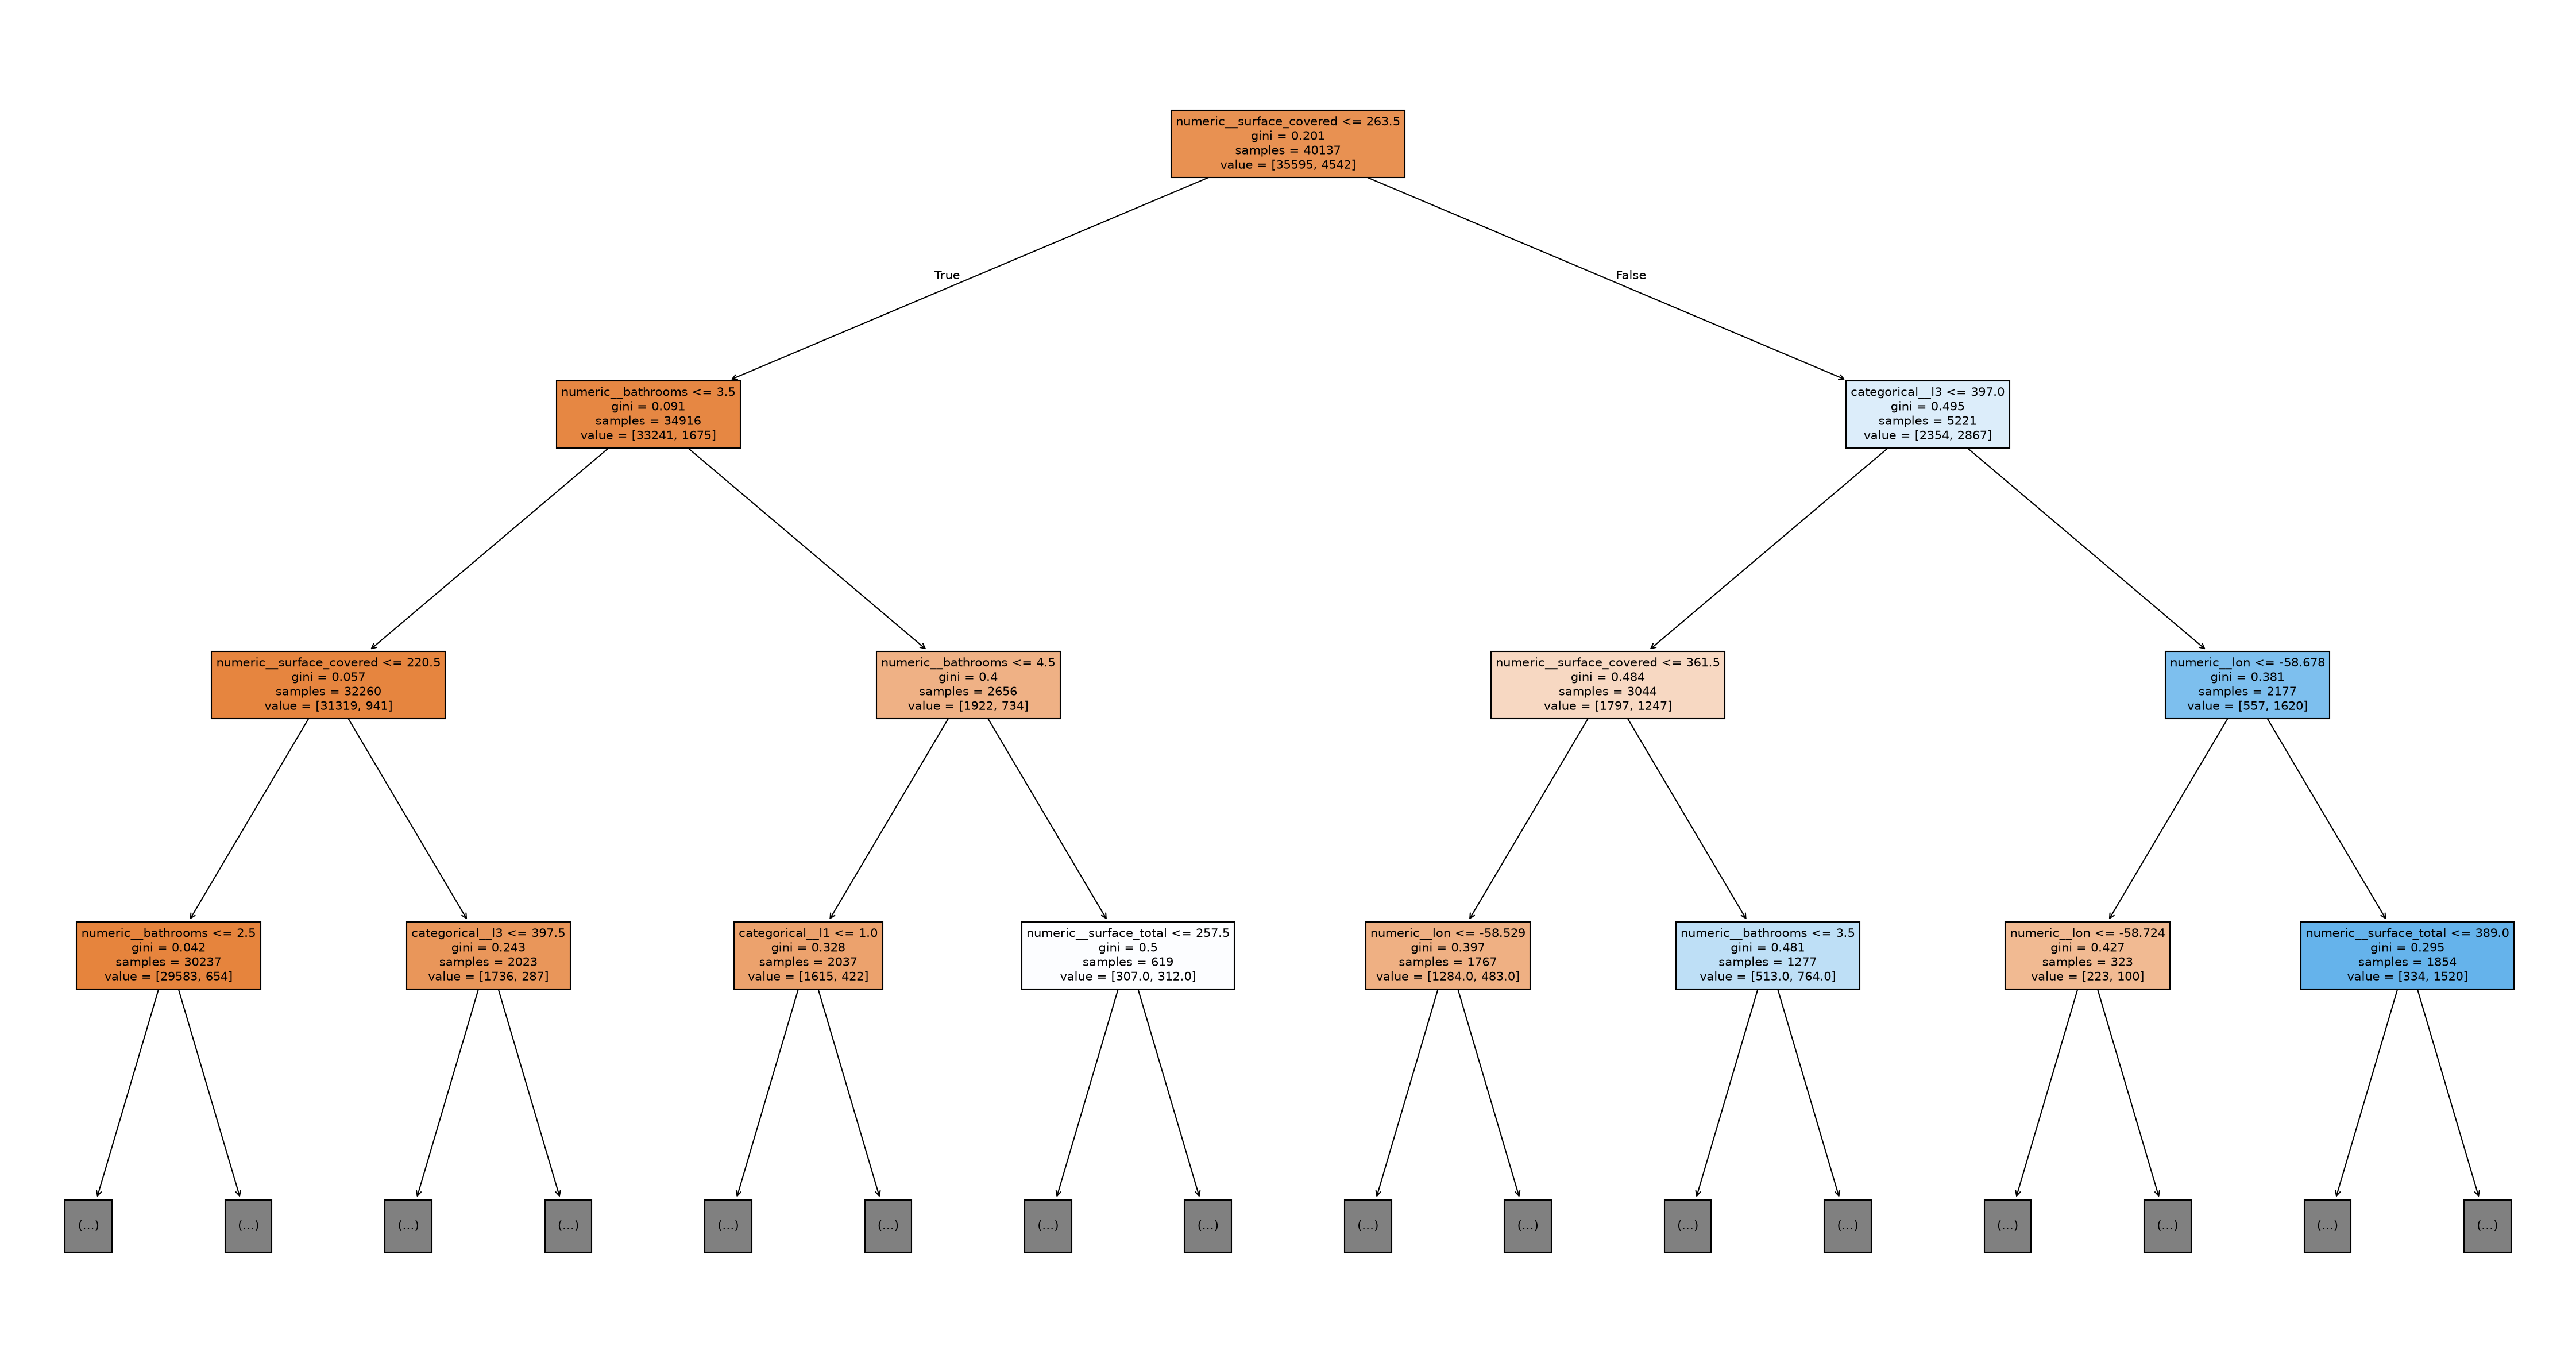

In [21]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score
from sklearn.tree import plot_tree

tree_pipeline.fit(X_train, y_train)
y_pred = tree_pipeline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["no paga", "paga"]))

feature_names = tree_pipeline.named_steps["preprocess"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(30, 16), dpi=150)
plot_tree(
    tree_pipeline.named_steps["model"],
    feature_names=feature_names,
    filled=True,
    max_depth=3, 
    fontsize=10,
    ax=ax,
)
plt.tight_layout()
plt.show()

### Ganancia

In [22]:
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[False, True]
).ravel()
money = 100 * tp - 50 * fp
print(f"True positives: {tp}, false positives: {fp}")
print(f"Payoff on test set: US${money:,.0f}")

True positives: 1192, false positives: 1155
Payoff on test set: US$61,450


It's trash

## Random Forest

With 1/3 cutoff

In [23]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = clone(tree_pipeline)

forest_pipeline.set_params(model=RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, max_features=0.5,
        n_jobs=-1, random_state=42,
    ))
forest_pipeline.fit(X_train, y_train)

paga_column = list(forest_pipeline.classes_).index(True)
prob_paga = forest_pipeline.predict_proba(X_test)[:, paga_column]
y_pred = prob_paga >= 1/3

print(classification_report(y_test, y_pred, target_names=["no paga", "paga"]))

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[False, True]
).ravel()
money = 100 * tp - 50 * fp
print(f"True positives: {tp}, false positives: {fp}")
print(f"Payoff on test set: US${money:,.0f}")


              precision    recall  f1-score   support

     no paga       0.97      0.96      0.96     15256
        paga       0.69      0.77      0.73      1946

    accuracy                           0.94     17202
   macro avg       0.83      0.86      0.85     17202
weighted avg       0.94      0.94      0.94     17202

True positives: 1505, false positives: 676
Payoff on test set: US$116,700


Still not good enough

## Gridsearch RF

In [24]:
import numpy as np
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def profit_score(model, X_val, y_val):
    prob_paga = model.predict_proba(X_val)[:, 1]
    predicted = prob_paga >= 1/3
    actual = np.asarray(y_val, dtype=bool)
    return (100 * np.sum(predicted & actual)
            - 50 * np.sum(predicted & ~actual)) / len(actual)

rf_for_search = clone(forest_pipeline).set_params(model__n_jobs=1)

search = GridSearchCV(
    rf_for_search,
    param_grid={
        "model__n_estimators": [150, 250],
        "model__min_samples_leaf": [2, 5],
        "model__max_features": ["sqrt", 0.5],
    },
    scoring=profit_score,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=2,
)

search.fit(X_train, y_train)
print(search.best_params_)
print(f"Cross-validation profit per house: US${search.best_score_:.2f}")

{'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 250}
Cross-validation profit per house: US$6.57


In [25]:
best_rf = search.best_estimator_
prob_paga = best_rf.predict_proba(X_test)[:, 1]
y_pred = prob_paga >= 1/3

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[False, True]
).ravel()

print(f"TP={tp}, FP={fp}")
print(f"Test profit: US${100 * tp - 50 * fp:,.0f}")

TP=1475, FP=591
Test profit: US$117,950


Takes x1000 more time for just 1k more profit. Trash

## Gradient Boosting

In [26]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

boost_pipeline = clone(tree_pipeline).set_params(
    model=GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=10,
        random_state=42,
    )
)
boost_pipeline.fit(X_train, y_train)

# y is boolean, so probability column 1 corresponds to "paga".
prob_paga_boost = boost_pipeline.predict_proba(X_test)[:, 1]
y_pred_boost = prob_paga_boost >= 1 / 3

print(classification_report(y_test, y_pred_boost, target_names=["no paga", "paga"]))
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_boost, labels=[False, True]
).ravel()
print(f"TP={tp}, FP={fp}")
print(f"Gradient boosting test profit: US${100 * tp - 50 * fp:,.0f}")


              precision    recall  f1-score   support

     no paga       0.96      0.97      0.97     15256
        paga       0.73      0.72      0.73      1946

    accuracy                           0.94     17202
   macro avg       0.85      0.84      0.85     17202
weighted avg       0.94      0.94      0.94     17202

TP=1404, FP=510
Gradient boosting test profit: US$114,900


Faster but worse

## Grid search: gradient boosting

Tune on `X_train` with stratified cross-validation and the same profit rule. `X_test` is used only after the search.


In [27]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def boost_profit_score(model, X_val, y_val):
    prob_paga = model.predict_proba(X_val)[:, 1]
    predicted = prob_paga >= 1 / 3
    actual = np.asarray(y_val, dtype=bool)
    return (100 * np.sum(predicted & actual)
            - 50 * np.sum(predicted & ~actual)) / len(actual)

# Profit per validation row makes scores comparable across folds.
boost_search = GridSearchCV(
    clone(boost_pipeline),
    param_grid={
        "model__n_estimators": [100, 150,200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
    scoring=boost_profit_score,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=2,
)
boost_search.fit(X_train, y_train)
print("Best parameters:", boost_search.best_params_)
print(f"CV profit per house: US${boost_search.best_score_:.2f}")


best_boost = boost_search.best_estimator_  # Already refitted on all of X_train.
prob_paga_boost_tuned = best_boost.predict_proba(X_test)[:, 1]
y_pred_boost_tuned = prob_paga_boost_tuned >= 1 / 3

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_boost_tuned, labels=[False, True]
).ravel()

print(classification_report(
    y_test, y_pred_boost_tuned, target_names=["no paga", "paga"]
))
print(f"TP={tp}, FP={fp}")
print(f"Tuned gradient boosting test profit: US${100 * tp - 50 * fp:,.0f}")

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100}
CV profit per house: US$6.06
              precision    recall  f1-score   support

     no paga       0.96      0.97      0.96     15256
        paga       0.72      0.67      0.69      1946

    accuracy                           0.93     17202
   macro avg       0.84      0.82      0.83     17202
weighted avg       0.93      0.93      0.93     17202

TP=1305, FP=516
Tuned gradient boosting test profit: US$104,700


## Feature-engineered random forest

This pipeline keeps title-based room and surface imputations, extracts an explicit USD price and property words from the title, converts dates to numeric features, and one-hot encodes location columns. All imputation and encoding are fitted on training rows inside the pipeline. The business cutoff stays fixed at 1/3.


In [44]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

class PreparePropertyFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        result = X.copy()
        title = result["title"].fillna("").astype(str).str.lower()

        # Prices such as "U$D 1.195.000" or "U$S 650000".
        price_text = title.str.extract(
            r"(?:u\s*\$\s*[sd]|usd|us\$)\s*([\d.,]+)", expand=False
        )
        price_digits = price_text.str.replace(r"[^\d]", "", regex=True)
        title_price = pd.to_numeric(price_digits, errors="coerce")
        result["title_usd_price"] = title_price.where(
            title_price.between(10_000, 100_000_000)
        )
        result["title_has_usd_price"] = result["title_usd_price"].notna().astype("int8")

        for word in ["casa", "departamento", "duplex", "ph", "terreno",
                     "quinta", "cochera", "pileta", "estrenar", "alquiler"]:
            result[f"title_{word}"] = title.str.contains(word, regex=False).astype("int8")

        start = pd.to_datetime(result["start_date"], errors="coerce")
        end = pd.to_datetime(
            result["end_date"].where(result["end_date"] != "9999-12-31"),
            errors="coerce",
        )
        result["start_day"] = (start - pd.Timestamp("2019-01-01")).dt.days
        result["start_month"] = start.dt.month
        result["listing_finished"] = end.notna().astype("int8")
        result["listing_days"] = (end - start).dt.days.clip(lower=0)
        result["price_period_reported"] = result["price_period"].notna().astype("int8")

        return result.drop(columns=[
            "title", "start_date", "end_date", "created_on", "price_period",
            "ad_type", "l5", "l6",
        ])

property_numeric = [
    "lat", "lon", "rooms", "bedrooms", "bathrooms", "surface_total",
    "surface_covered", "title_usd_price", "title_has_usd_price",
    "start_day", "start_month", "listing_finished", "listing_days",
    "price_period_reported",
] + [f"title_{word}" for word in [
    "casa", "departamento", "duplex", "ph", "terreno",
    "quinta", "cochera", "pileta", "estrenar", "alquiler",
]]
property_categorical = ["l1", "l2", "l3", "l4"]

property_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True), property_numeric),
    ("location", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ]), property_categorical),
])

rich_forest_pipeline = Pipeline([
    ("rooms_bedrooms_from_title", TitleRoomBedroomImputer()),
    ("surface_from_title", TitleSurfaceImputer()),
    ("prepare_features", PreparePropertyFeatures()),
    ("preprocess", property_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, max_features=0.5,
        n_jobs=-1, random_state=42,
    )),
])


In [ ]:
rich_forest_pipeline.fit(X_train, y_train)
paga_column = list(rich_forest_pipeline.classes_).index(True)
rich_prob_paga = rich_forest_pipeline.predict_proba(X_test)[:, paga_column]
rich_pred = rich_prob_paga >= 1/3

print(classification_report(y_test, rich_pred, target_names=["no paga", "paga"]))
tn, fp, fn, tp = confusion_matrix(y_test, rich_pred, labels=[False, True]).ravel()
print(f"TP={tp}, FP={fp}")
print(f"Feature-engineered forest test profit: US${100 * tp - 50 * fp:,.0f}")


              precision    recall  f1-score   support

     no paga       0.98      0.95      0.96     15256
        paga       0.68      0.85      0.76      1946

    accuracy                           0.94     17202
   macro avg       0.83      0.90      0.86     17202
weighted avg       0.95      0.94      0.94     17202

TP=1649, FP=765
Feature-engineered forest test profit: US$126,650


## Grid search: feature-engineered forest

Search a small parameter grid on `X_train` using three stratified folds. The score is profit per validation listing at the fixed 1/3 cutoff; `X_test` is evaluated after the search.


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def rich_profit_score(model, X_val, y_val):
    paga_column = list(model.classes_).index(True)
    prob_paga = model.predict_proba(X_val)[:, paga_column]
    predicted = prob_paga >= 1/3
    actual = np.asarray(y_val, dtype=bool)
    return (100 * np.sum(predicted & actual)
            - 50 * np.sum(predicted & ~actual)) / len(actual)

rich_search = GridSearchCV(
    clone(rich_forest_pipeline).set_params(model__n_estimators=150, model__n_jobs=1),
    param_grid={
        "model__min_samples_leaf": [2, 5],
        "model__max_features": ["sqrt", 0.5],
    },
    scoring=rich_profit_score,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=2,
)
rich_search.fit(X_train, y_train)
print("Best parameters:", rich_search.best_params_)
print(f"CV profit per listing: US${rich_search.best_score_:.2f}")


Best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 2}
CV profit per listing: US$7.08


In [ ]:
best_rich_forest = rich_search.best_estimator_  # Already refitted on X_train.
paga_column = list(best_rich_forest.classes_).index(True)
rich_tuned_prob = best_rich_forest.predict_proba(X_test)[:, paga_column]
rich_tuned_pred = rich_tuned_prob >= 1/3

tn, fp, fn, tp = confusion_matrix(
    y_test, rich_tuned_pred, labels=[False, True]
).ravel()
print(f"TP={tp}, FP={fp}")
print(f"Grid-searched feature forest test profit: US${100 * tp - 50 * fp:,.0f}")


TP=1649, FP=765
Grid-searched feature forest test profit: US$126,650


## Location target encoding

`X_train` contains the features, while `y_train` contains the matching labels. When this pipeline is fitted with `fit(X_train, y_train)`, the target encoder receives both through the pipeline. Its internal cross-fitting prevents each training row from being encoded with its own label. Prediction rows need features only.


In [32]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import TargetEncoder

# Broad regions stay one-hot; the many-valued l3/l4 columns get target encoding.
target_location_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True), property_numeric),
    ("broad_location", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), ["l1", "l2"]),
    ("local_location", TargetEncoder(
        target_type="binary", cv=StratifiedKFold(
            n_splits=5, shuffle=True, random_state=42
        ), smooth="auto"
    ), ["l3", "l4"]),
])

target_location_forest = Pipeline([
    ("rooms_bedrooms_from_title", TitleRoomBedroomImputer()),
    ("surface_from_title", TitleSurfaceImputer()),
    ("prepare_features", PreparePropertyFeatures()),
    ("preprocess", target_location_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, max_features=0.5,
        n_jobs=-1, random_state=42,
    )),
])


In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

def target_location_profit(model, X_val, y_val):
    paga_column = list(model.classes_).index(True)
    probability = model.predict_proba(X_val)[:, paga_column]
    predicted = probability >= 0.2
    actual = np.asarray(y_val, dtype=bool)
    return (100 * np.sum(predicted & actual)
            - 50 * np.sum(predicted & ~actual)) / len(actual)

location_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
location_cv_scores = cross_val_score(
    target_location_forest, X_train, y_train,
    cv=location_cv, scoring=target_location_profit, n_jobs=1,
)
print("Target-encoded location CV profit per listing:",
      np.round(location_cv_scores, 2))
print(f"Mean: US${location_cv_scores.mean():.2f}")
print("One-hot location forest CV reference: US$7.28 per listing")


Target-encoded location CV profit per listing: [7.42 7.38 7.38]
Mean: US$7.40
One-hot location forest CV reference: US$7.28 per listing


In [39]:
from sklearn.metrics import classification_report, confusion_matrix

target_location_forest.fit(X_train, y_train)
paga_column = list(target_location_forest.classes_).index(True)
target_location_prob = target_location_forest.predict_proba(X_test)[:, paga_column]
target_location_pred = target_location_prob >= 1 / 3

print(classification_report(
    y_test, target_location_pred, target_names=["no paga", "paga"]
))
tn, fp, fn, tp = confusion_matrix(
    y_test, target_location_pred, labels=[False, True]
).ravel()
print(f"TP={tp}, FP={fp}")
print(f"Target-encoded location forest test profit: US${100 * tp - 50 * fp:,.0f}")


              precision    recall  f1-score   support

     no paga       0.97      0.97      0.97     15256
        paga       0.76      0.80      0.78      1946

    accuracy                           0.95     17202
   macro avg       0.87      0.89      0.88     17202
weighted avg       0.95      0.95      0.95     17202

TP=1565, FP=487
Target-encoded location forest test profit: US$132,150


## Forest + title-text logistic model

A soft vote averages the two models' probabilities equally. The forest receives the existing engineered property and location features; the logistic model receives TF-IDF features from `title` only. Both models are fitted on `X_train` inside the ensemble. Apply the business cutoff of 1/3 to the averaged probability.


In [132]:
from sklearn.ensemble import VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

class SelectTitleText(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X["title"].fillna("").astype(str)

title_text_pipeline = Pipeline([
    ("title_only", SelectTitleText()),
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2), min_df=5, max_features=20_000,
        strip_accents="unicode", sublinear_tf=True,
    )),
    ("model", LogisticRegression(max_iter=1000)),
])

forest_title_ensemble = VotingClassifier(
    estimators=[
        ("forest", target_location_forest),
        ("title_logistic", title_text_pipeline),
    ],
    voting="soft",
    weights=[1, 1],
)


NameError: name 'target_location_forest' is not defined

In [133]:
forest_title_ensemble.fit(X_train, y_train)

# predict_proba returns one column per class; select the True ("paga") column.
paga_column = list(forest_title_ensemble.classes_).index(True)
ensemble_prob_paga = forest_title_ensemble.predict_proba(X_test)[:, paga_column]
ensemble_pred = ensemble_prob_paga >= 1 / 3

print(classification_report(
    y_test, ensemble_pred, target_names=["no paga", "paga"]
))
tn, fp, fn, tp = confusion_matrix(
    y_test, ensemble_pred, labels=[False, True]
).ravel()
print(f"TP={tp}, FP={fp}")
print(f"Forest + title-text logistic test profit: US${100 * tp - 50 * fp:,.0f}")


NameError: name 'forest_title_ensemble' is not defined

## ROC curves for the fitted models

Compare the eight models above on the same held-out test set. The Forest + title-text logistic ensemble is excluded.

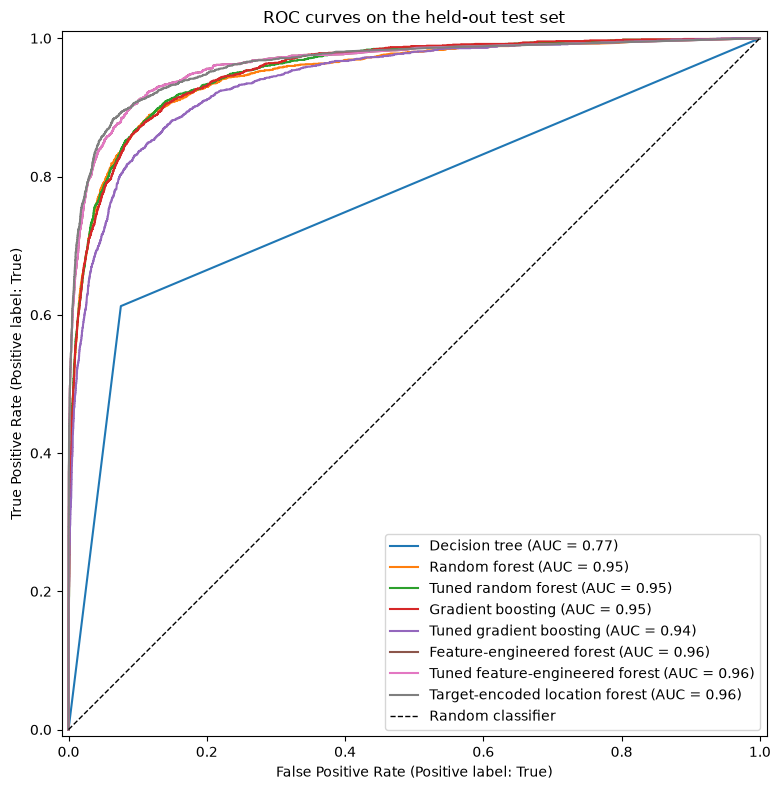

In [49]:
from sklearn.metrics import RocCurveDisplay

# Use positive-class probabilities, independent of each model's profit cutoff.
roc_scores = {
    "Decision tree": tree_pipeline.predict_proba(X_test)[
        :, list(tree_pipeline.classes_).index(True)
    ],
    "Random forest": forest_pipeline.predict_proba(X_test)[
        :, list(forest_pipeline.classes_).index(True)
    ],
    "Tuned random forest": best_rf.predict_proba(X_test)[
        :, list(best_rf.classes_).index(True)
    ],
    "Gradient boosting": prob_paga_boost,
    "Tuned gradient boosting": prob_paga_boost_tuned,
    "Feature-engineered forest": rich_prob_paga,
    "Tuned feature-engineered forest": rich_tuned_prob,
    "Target-encoded location forest": target_location_prob,
}

fig, ax = plt.subplots(figsize=(10, 8))
for name, scores in roc_scores.items():
    RocCurveDisplay.from_predictions(
        y_test, scores, pos_label=True, name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier")
ax.set_title("ROC curves on the held-out test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
